# Eleições presidenciais — resultados do 1º e 2º turnos

Fonte: TSE (votação por seção eleitoral e detalhe da apuração), processados por
`python -m eleicoes.processar`. O ano vem do `config.yaml`.

O notebook detecta sozinho os turnos disponíveis: quando o TSE publicar o 2º turno, rode
`python -m eleicoes.baixar --forcar` e `python -m eleicoes.processar` e execute tudo de novo.
As figuras também são salvas em `figuras/`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from eleicoes import graficos as gr
from eleicoes import resultados as r
from eleicoes.config import config
from eleicoes.dados import (
    ORDEM_REGIOES,
    carregar_comparecimento,
    carregar_malha,
    carregar_votos,
    municipios_ibge,
)

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
%matplotlib inline

ANO = int(config()["ano_principal"])
df = carregar_votos(ANO)
comp = carregar_comparecimento(ANO)  # None se o detalhe da apuração não foi processado
TURNOS = r.turnos(df)
fin = r.finalistas(df)
NOME_A, NOME_B = r.rotulos(fin)
print(
    f"Eleição {ANO} | turnos disponíveis: {TURNOS} | finalistas: {NOME_A} ({fin['A']}) e {NOME_B} ({fin['B']})"
)
print("Abstenção:", "disponível" if comp is not None else "baixe e processe o detalhe da apuração")

Eleição 2026 | turnos disponíveis: [1, 2] | finalistas: Flavio Bolsonaro (22) e Lula (13)
Abstenção: disponível


s:\developer\data-analise-eleicoes\eleicoes2026\eleicoes2026\.venv\Lib\site-packages\pandera\backends\pandas\container.py:338: SchemaWarning: DataFrameSchema 'comparecimento_municipio' failed element-wise validator number 0: <Check <lambda>: aptos = comparecimento + abstenções> failure cases: 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, ZZ, 29424, 29521, 29629, 29769, 29815, 29823, 29831, 29874, 29939, 29963, 30669, 30929, 30988, 38881, 38903, 38920, 38989, 39128, 39187, 39225, 39241, 39263, 39284, 99104, 99139, 99147, 99171, 99198, 99210, 99236, 99244, 99279, 99287, 99295, 99325, 99333, 99341, 99350, 99376, 99384, 22, 27, 1, 7, 14, 17, 18, 27, 18, 7, 10, 12, 11, 13, 5, 8, 13, 5, 2, 18, 13, 5, 6, 29, 9, 1, 10, 3, 1, 8, 19, 1, 25, 1, 3, 10, 6, 5, 6, 7, 0, 0, 0

## 1. Resultado nacional e participação

In [2]:
r.resumo_nacional(df)

,turno,nr,nome,tipo,votos,pct_validos,pct_total
0,1,22,FLAVIO NANTES BOLSONARO,Nominal,56104503,47.03,44.78
1,1,13,LUIZ INÁCIO LULA DA SILVA,Nominal,53879538,45.16,43.01
2,1,96,VOTO NULO,Nulo,3669003,NaN,2.93
3,1,70,AUGUSTO JORGE CURY,Nominal,3448569,2.89,2.75
4,1,14,RENAN ANTONIO FERREIRA DOS SANTOS,Nominal,2675887,2.24,2.14
5,1,55,RONALDO RAMOS CAIADO,Nominal,2605148,2.18,2.08
6,1,95,VOTO BRANCO,Branco,2300798,NaN,1.84
7,1,30,ROMEU ZEMA NETO,Nominal,326488,0.27,0.26
8,1,80,SAMARA MARTINS DA SILVA FEITOSA,Nominal,122911,0.10,0.10
9,1,16,HERTZ DA CONCEICAO DIAS,Nominal,43103,0.04,0.03


In [3]:
# Votos totais, brancos e nulos; com o detalhe da apuração, também aptos e abstenção
r.participacao(df, comp)

,votos_totais,validos,brancos,nulos,pct_brancos,pct_nulos,qt_aptos,qt_comparecimento,qt_abstencoes,pct_abstencao
NR_TURNO,,,,,,,,,,
1,125275835,119306034,2300798,3669003,1.84,2.93,"158,745,502.00","125,275,835.00","33,469,244.00",21.08
2,128236074,124082273,1430496,2723305,1.12,2.12,NaN,NaN,NaN,NaN


## 2. Distribuição do voto por região

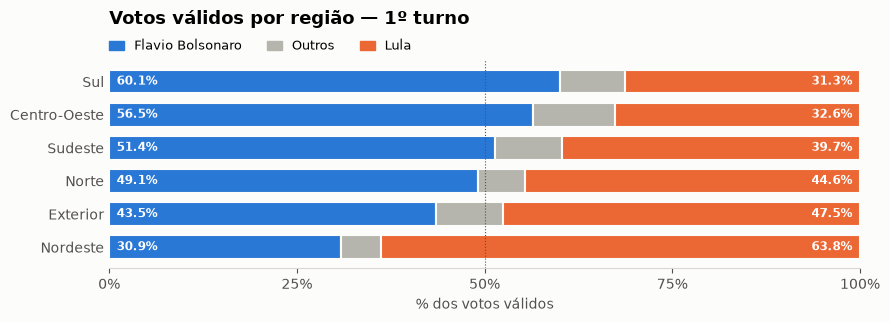

grupo,validos,Flavio Bolsonaro,Lula,Outros
REGIAO,,,,
Norte,10192323,49.15,44.65,6.20
Nordeste,33705898,30.85,63.77,5.38
Centro-Oeste,9084532,56.51,32.62,10.88
Sudeste,48482385,51.36,39.68,8.96
Sul,17509891,60.08,31.28,8.65
Exterior,331005,43.47,47.55,8.98


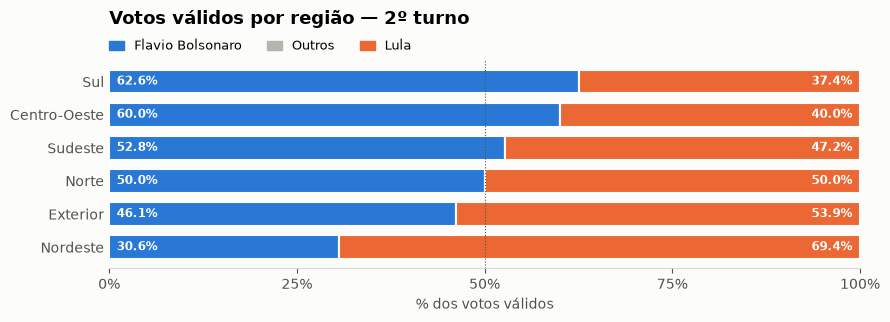

grupo,validos,Flavio Bolsonaro,Lula,Outros
REGIAO,,,,
Norte,10048173,49.99,50.01,0.00
Nordeste,35247168,30.63,69.37,0.00
Centro-Oeste,9337786,60.01,39.99,0.00
Sudeste,50882232,52.76,47.24,0.00
Sul,18195263,62.58,37.42,0.00
Exterior,371651,46.14,53.86,0.00


In [4]:
for t in TURNOS:
    tab = r.percentuais(df, t, "REGIAO", fin)
    tab = tab.reindex([x for x in ORDEM_REGIOES if x in tab.index])
    gr.barras_empilhadas(tab, fin, f"Votos válidos por região — {t}º turno", f"regiao_turno{t}")
    plt.show()
    display(
        tab[["validos", "pct_A", "pct_B", "pct_Outros"]].rename(
            columns={"pct_A": NOME_A, "pct_B": NOME_B, "pct_Outros": "Outros"}
        )
    )

## 3. Distribuição do voto por UF

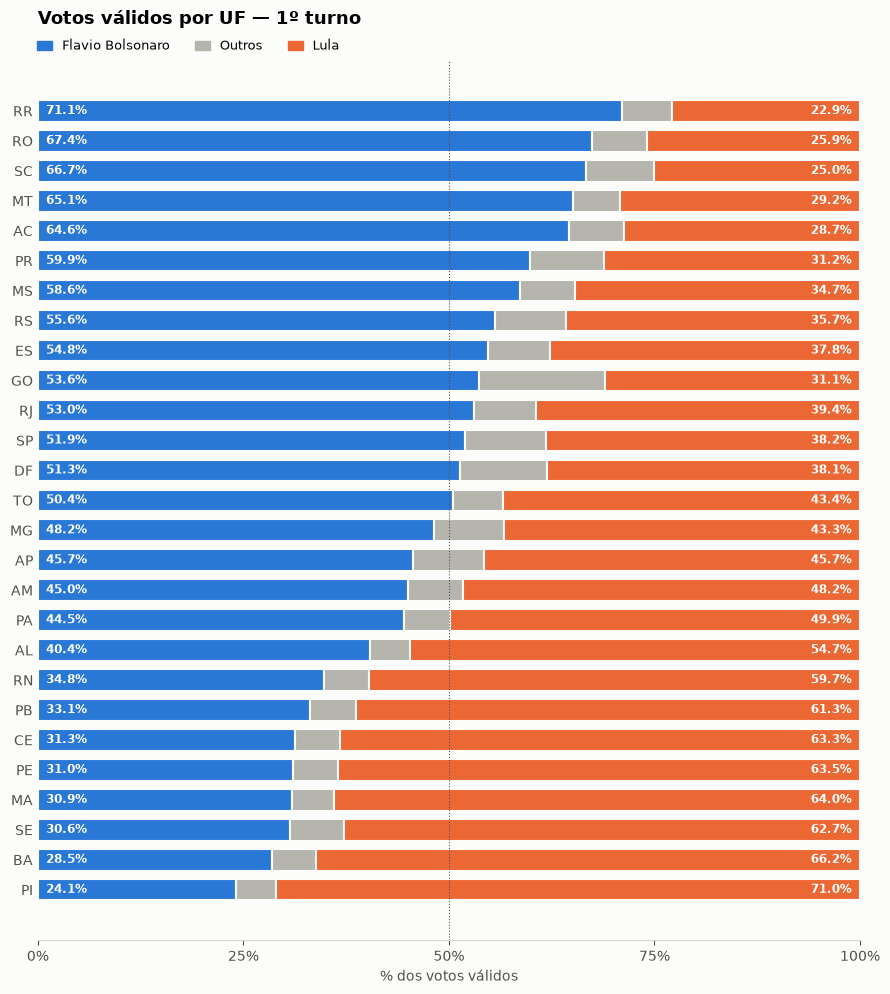

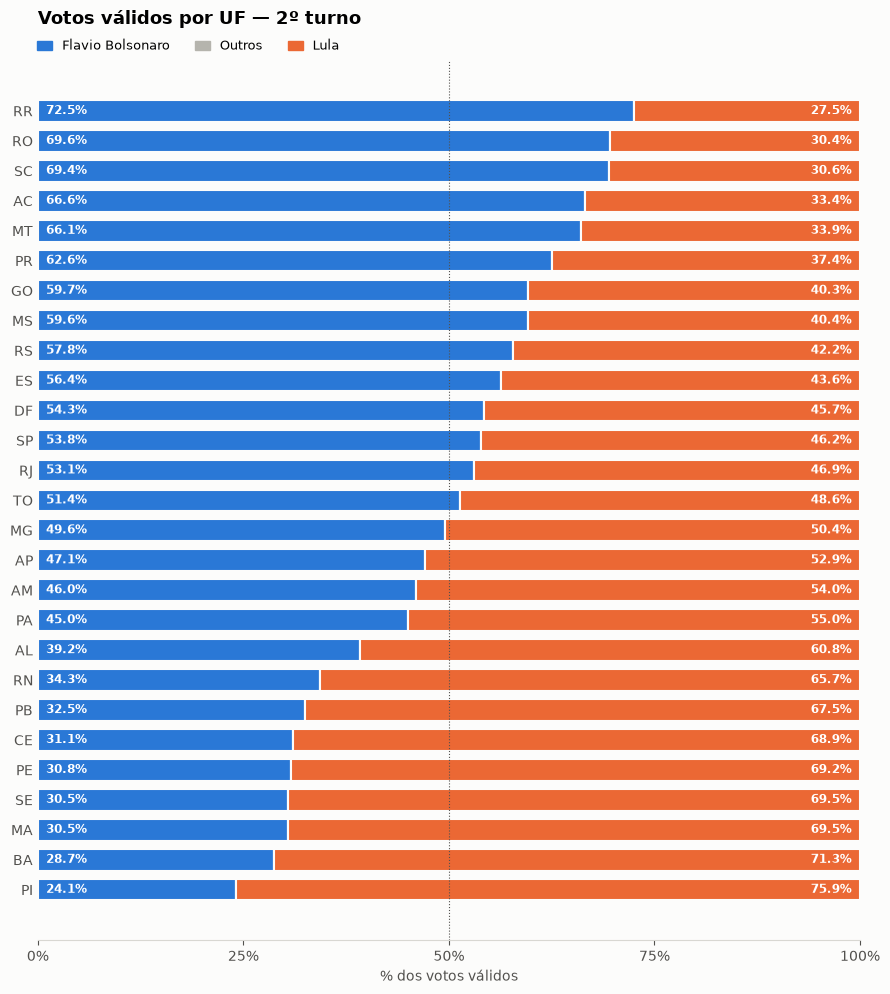

In [5]:
for t in TURNOS:
    tab = r.percentuais(df, t, "SG_UF", fin).drop(["ZZ", "VT"], errors="ignore")
    gr.barras_empilhadas(tab, fin, f"Votos válidos por UF — {t}º turno", f"uf_turno{t}")
    plt.show()

## 4. Abstenção

Percentual de eleitores aptos que não votaram. Requer o arquivo *Detalhe da apuração por
município e zona*.

NR_TURNO,turno1
REGIAO,
Norte,19.43
Nordeste,18.39
Centro-Oeste,21.70
Sudeste,22.70
Sul,20.46
Exterior,62.66


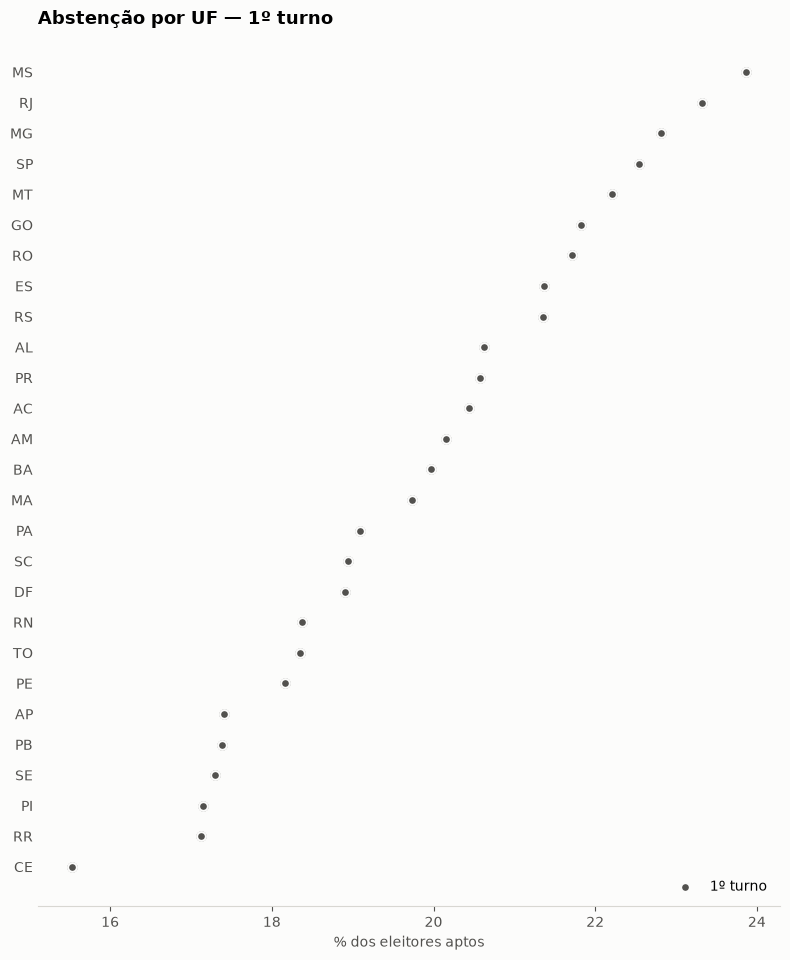

In [6]:
if comp is None:
    print("Sem o detalhe da apuração. Rode: python -m eleicoes.baixar && python -m eleicoes.processar")
else:
    ab_reg = r.abstencao(comp, "REGIAO").reindex([x for x in ORDEM_REGIOES if x in set(comp["REGIAO"])])
    display(ab_reg)
    ab_uf = r.abstencao(comp, "SG_UF").drop(["ZZ", "VT"], errors="ignore")
    if "turno2" in ab_uf:
        gr.halteres(
            ab_uf,
            "turno1",
            "turno2",
            "Abstenção por UF: 1º → 2º turno",
            "abstencao_uf",
            cor=gr.COR_TEXTO_2,
            xlabel="% dos eleitores aptos",
        )
    else:
        gr.halteres(
            ab_uf.assign(t=ab_uf["turno1"]),
            "turno1",
            "t",
            "Abstenção por UF — 1º turno",
            "abstencao_uf",
            rotulo_ini="",
            rotulo_fim="1º turno",
            cor=gr.COR_TEXTO_2,
            xlabel="% dos eleitores aptos",
        )
    plt.show()

KeyError: 'turno2'

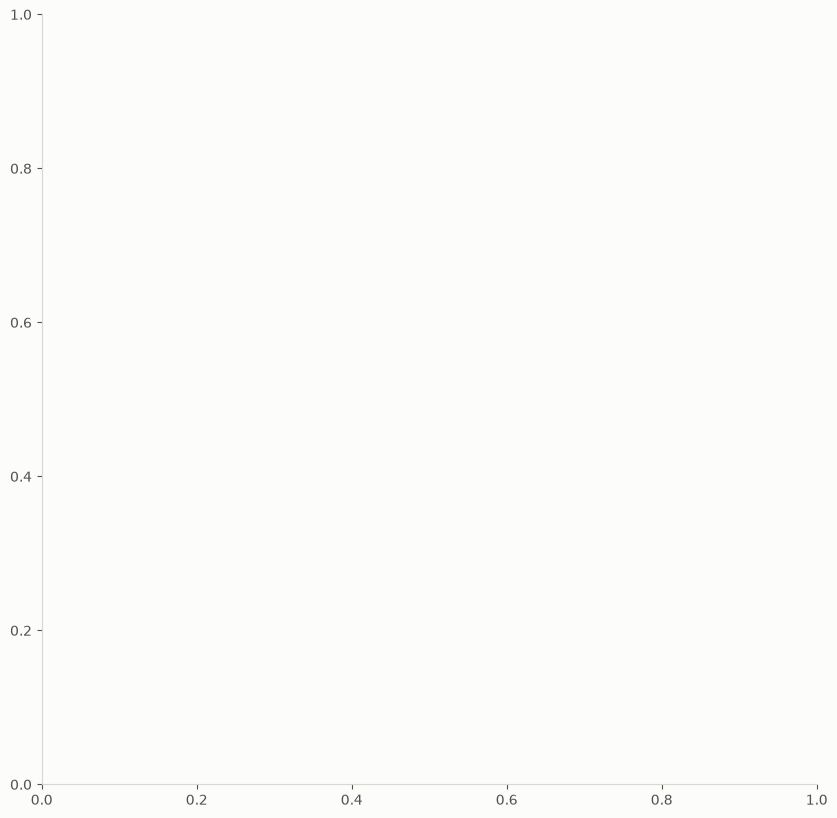

In [7]:
if comp is not None:
    malha = carregar_malha()
    ab_mun = r.abstencao(comp[~comp["SG_UF"].isin(["ZZ", "VT"])], "CD_MUNICIPIO").reset_index()
    t = TURNOS[-1]
    gr.mapa_continuo(
        malha.merge(ab_mun, on="CD_MUNICIPIO", how="left"),
        f"turno{t}",
        f"Abstenção por município — {t}º turno",
        f"mapa_abstencao_turno{t}",
        limite=40,
        rotulo="% dos eleitores aptos que não votaram",
        centro=None,
    )
    plt.show()

## 5. Mapas: quem venceu em cada município

**Mapa por área:** azul = vantagem de A, laranja = vantagem de B; quanto mais forte a cor,
maior a margem. Municípios vencidos por outro candidato aparecem hachurados.

**Mapa proporcional:** no mapa por área, municípios enormes e pouco populosos da Amazônia
dominam a imagem e São Paulo vira um ponto. No mapa de círculos, a área de cada círculo é
proporcional aos votos válidos: ele mostra onde os votos realmente estão.

In [ ]:
malha = carregar_malha()
coords = municipios_ibge()
MUN = {}
for t in TURNOS:
    MUN[t] = r.municipios(df, t, fin)
    gr.mapa_margem(MUN[t], malha, fin, t)
    plt.show()
    gr.mapa_proporcional(MUN[t], malha, coords, fin, t)
    plt.show()

In [ ]:
for t in TURNOS:
    m = MUN[t]
    print(f"--- {t}º turno ---")
    display(
        m.groupby("nome_vencedor")
        .agg(
            municipios=("CD_MUNICIPIO", "count"),
            votos_validos=("validos", "sum"),
            margem_mediana_pp=("margem_pp", "median"),
            vitorias_acima_de_40pp=("margem_pp", lambda s: (s > 40).sum()),
        )
        .sort_values("municipios", ascending=False)
    )

In [ ]:
# Disputas mais apertadas entre municípios grandes (>= 50 mil votos válidos)
t = TURNOS[-1]
(
    MUN[t][MUN[t]["validos"] >= 50_000].nsmallest(15, "margem_pp")[
        ["SG_UF", "NM_MUNICIPIO", "validos", "nome_vencedor", "pct_vencedor", "margem_pp"]
    ]
)

## 6. Onde se concentraram os votos dos demais candidatos (1º turno)

É o eleitorado disputado no 2º turno. Entram os não finalistas com pelo menos 1% dos válidos.

In [ ]:
MENORES = r.candidatos_menores(df, fin, minimo_pct=1.0)
pcts = {fin["rotulos"][n]: r.pct_candidato(df, n) for n in MENORES}
nac = {fin["rotulos"][n]: r.pct_nacional(df, n) for n in MENORES}
if MENORES:
    gr.menores_uf(
        pcts, nac, "Onde se concentraram os votos dos demais candidatos — 1º turno", "candidatos_menores_uf"
    )
    plt.show()

In [ ]:
for nr in MENORES:
    print(fin["rotulos"][nr])
    display(r.top_municipios(df, nr, n=10, min_validos=10_000))

## 7. Do 1º para o 2º turno

Só roda quando os dados já tiverem o 2º turno. A estimativa formal de transferência de votos
(por seção eleitoral, com intervalo de confiança) está no notebook `02_ciencia_de_dados`.

In [ ]:
if 2 in TURNOS:
    var = r.variacao_uf(df, fin)
    gr.halteres(
        var,
        "pct_A_t1",
        "pct_A_t2",
        f"{NOME_A}: % dos válidos no 1º e no 2º turno, por UF",
        "variacao_uf",
        xlabel="% dos votos válidos",
        ref=50,
    )
    plt.show()
    display(var.sort_values("ganho_A", ascending=False))
else:
    print("2º turno ainda não está nos dados.")

In [ ]:
if 2 in TURNOS:
    gr.dispersao_transferencia(r.transferencia_municipal(df, fin), fin)
    plt.show()

In [ ]:
if 2 in TURNOS:
    v = r.viradas(MUN[1], MUN[2])
    print(f"{len(v)} municípios mudaram de vencedor")
    display(v.head(20))

## Notas metodológicas
- Percentuais sobre votos válidos (sem brancos e nulos), como no resultado oficial.
- Exterior (`ZZ`) e voto em trânsito (`VT`) entram nos totais nacionais e regionais, não nos mapas.
- Malha municipal de 2010 (IBGE): os poucos municípios criados depois aparecem em cinza.
- Dados agregados: padrões entre municípios não descrevem o voto individual (falácia ecológica).